# MobileNetV2 Accident Detection — VS Code

This notebook trains **MobileNetV2** using transfer learning on your existing local dataset.

## Before running
1. Open this notebook from the project's `notebooks/` folder.
2. Select your project's `.venv` Python interpreter in VS Code.
3. Install dependencies using `pip install -r requirements.txt`.
4. Check `DATA_DIR` and `CLASS_NAMES` in the setup cell.
5. Run cells from top to bottom.

Class mapping is `non_accident = 0`, `accident = 1`. The folder names must match exactly. The test set is reserved for final evaluation.


In [1]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

MODEL_NAME = "MobileNetV2"
MODEL_CLASS = MobileNetV2
CHECKPOINT_FILENAME = "mobilenetv2_best.keras"
HISTORY_FILENAME = "mobilenetv2_history.csv"
CURVES_FILENAME = "mobilenetv2_training_curves.png"
CM_FILENAME = "mobilenetv2_confusion_matrix.png"
METRICS_FILENAME = "mobilenetv2_metrics.csv"
PREDICTIONS_FILENAME = "mobilenetv2_test_predictions.npz"


c:\Users\megha\AppData\Local\Programs\Python\Python310\lib\site-packages\google\api_core\_python_version_support.py:242: FutureWarning: You are using a non-supported Python version (3.10.11). Google will not post any further updates to google.api_core supporting this Python version. Please upgrade to the latest Python version, or at least Python 3.11, and then update google.api_core.
  warnings.warn(message, FutureWarning)

A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.2.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "c:\Users\megha\AppData\Local\Programs\Python\Python310\lib\runpy.py", line 196, in _run_modul

AttributeError: _ARRAY_API not found

In [6]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
EPOCHS = 10

# Notebook is expected inside <project_root>/notebooks/
PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

# EDIT if your dataset is stored elsewhere.
DATA_DIR = PROJECT_DIR / "datasets" / "data"
TRAIN_DIR, VAL_DIR, TEST_DIR = DATA_DIR / "train", DATA_DIR / "val", DATA_DIR / "test"
MODEL_DIR, RESULT_DIR = PROJECT_DIR / "models", PROJECT_DIR / "results"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

# These folder names must match exactly. Accident is positive class (index 1).
CLASS_NAMES = ["Accident","Non Accident"]
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))
print("Project directory:", PROJECT_DIR)
print("Dataset directory:", DATA_DIR)
print("Class mapping:", {name: i for i, name in enumerate(CLASS_NAMES)})


TensorFlow: 2.21.0
Available GPUs: []
Project directory: c:\Users\megha\OneDrive\Desktop\New folder\accident-detection
Dataset directory: c:\Users\megha\OneDrive\Desktop\New folder\accident-detection\datasets\data
Class mapping: {'Accident': 0, 'Non Accident': 1}


In [7]:
# Validate dataset folders and count image files
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".gif"}

for folder in (TRAIN_DIR, VAL_DIR, TEST_DIR):
    if not folder.is_dir():
        raise FileNotFoundError(
            f"Folder not found: {folder}. Update DATA_DIR in the setup cell."
        )
    found = sorted(p.name for p in folder.iterdir() if p.is_dir())
    if sorted(found) != sorted(CLASS_NAMES):
        raise ValueError(f"Expected {CLASS_NAMES} in {folder}; found {found}")

def count_images(folder):
    return {
        cls: sum(1 for p in (folder / cls).rglob("*")
                 if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS)
        for cls in CLASS_NAMES
    }

print("Train:", count_images(TRAIN_DIR))
print("Validation:", count_images(VAL_DIR))
print("Test:", count_images(TEST_DIR))

def load_dataset(folder, shuffle):
    return tf.keras.utils.image_dataset_from_directory(
        str(folder), class_names=CLASS_NAMES, label_mode="binary",
        image_size=IMG_SIZE, batch_size=BATCH_SIZE,
        shuffle=shuffle, seed=SEED
    )

train_raw = load_dataset(TRAIN_DIR, True)
val_raw = load_dataset(VAL_DIR, False)
test_raw = load_dataset(TEST_DIR, False)
AUTOTUNE = tf.data.AUTOTUNE


Train: {'Accident': 369, 'Non Accident': 422}
Validation: {'Accident': 46, 'Non Accident': 52}
Test: {'Accident': 31, 'Non Accident': 53}
Found 791 files belonging to 2 classes.
Found 98 files belonging to 2 classes.
Found 84 files belonging to 2 classes.


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 11s 1us/step


Model: "MobileNetV2_Accident"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 1280)           │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Starting MobileNetV2 training...
Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 282ms/step - accuracy: 0.5126 - auc: 0.5460 - loss: 0.8321 - precision: 0.5474 - recall: 0.5171
Epoch 1: val_auc improved from None to 0.74895, saving model to c:\Users\megha\OneDrive\Desktop\New folder\accident-detection\models\mobilenetv2_best.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 34s 426ms/step - accuracy: 0.5740 - auc: 0.5983 - loss: 0.7399 - precision: 0.5973 - recall: 0.6185 - val_accuracy: 0.7143 - val_auc: 0.7490 - val_loss: 0.5842 - val_precision: 0.7143 - val_recall: 0.7692 - learning_rate: 0.0010
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 276ms/step - accuracy: 0.6620 - auc: 0.7394 - loss: 0.5951 - precision: 0.6579 - recall: 0.7070
Epoch 2: val_auc improved from 0.74895 to 0.82901, saving model to c:\Users\megha\OneDrive\Desktop\New folder\accident-detection\models\mobilenetv2_best.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 17s 333ms/step - accuracy: 0.6802 - auc: 0.7534 - loss: 0.5813 - precision: 0.6849 - recall: 0.

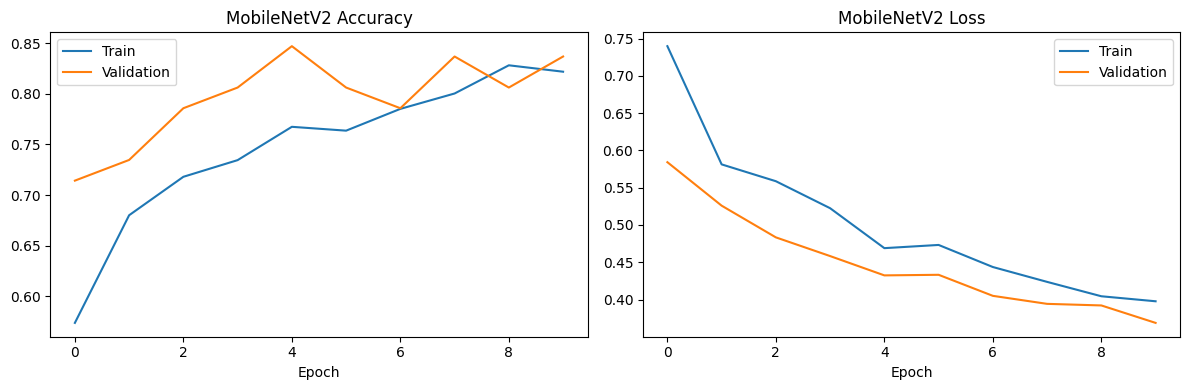

6/6 ━━━━━━━━━━━━━━━━━━━━ 7s 811ms/step
\nMobileNetV2 — TEST RESULTS
model: MobileNetV2
accuracy: 0.9048
precision: 0.8947
recall: 0.9623
f1_score: 0.9273
roc_auc: 0.9343
test_images: 84
training_seconds: 187.3709
test_prediction_seconds: 6.8849
seconds_per_image: 0.0820
\nClassification report:
              precision    recall  f1-score   support

    Accident       0.93      0.81      0.86        31
Non Accident       0.89      0.96      0.93        53

    accuracy                           0.90        84
   macro avg       0.91      0.88      0.89        84
weighted avg       0.91      0.90      0.90        84



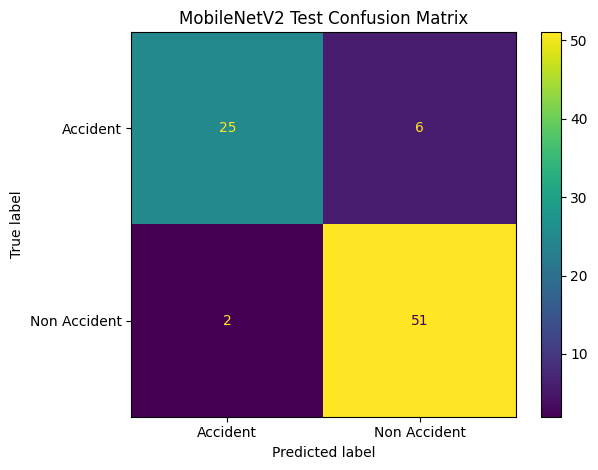

\nFinished.
Best model: c:\Users\megha\OneDrive\Desktop\New folder\accident-detection\models\mobilenetv2_best.keras
Results folder: c:\Users\megha\OneDrive\Desktop\New folder\accident-detection\results


In [8]:
# Model-specific preprocessing (preprocess_input is imported in the first cell)
def preprocess_data(images, labels):
    return preprocess_input(tf.cast(images, tf.float32)), labels

train_ds = train_raw.map(preprocess_data, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
val_ds = val_raw.map(preprocess_data, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
test_ds = test_raw.map(preprocess_data, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

# Build pretrained CNN and binary classification head
base_model = MODEL_CLASS(
    weights="imagenet", include_top=False,
    input_shape=(224, 224, 3), pooling="avg"
)
base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)
x = layers.Dropout(0.30)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model = Model(inputs, outputs, name=MODEL_NAME + "_Accident")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc"),
    ],
)
model.summary()

# Train; keep the checkpoint selected using validation AUC
checkpoint_path = MODEL_DIR / CHECKPOINT_FILENAME
callbacks = [
    ModelCheckpoint(str(checkpoint_path), monitor="val_auc", mode="max",
                    save_best_only=True, verbose=1),
    EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True,
                  verbose=1),
    ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=2,
                      min_lr=1e-6, verbose=1),
]

print(f"Starting {MODEL_NAME} training...")
start_time = time.time()
history = model.fit(train_ds, validation_data=val_ds,
                    epochs=EPOCHS, callbacks=callbacks)
training_seconds = time.time() - start_time
print(f"Training time: {training_seconds / 60:.2f} minutes")

pd.DataFrame(history.history).to_csv(
    RESULT_DIR / HISTORY_FILENAME, index_label="epoch"
)

# Plot training curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["accuracy"], label="Train")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title(f"{MODEL_NAME} Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[1].plot(history.history["loss"], label="Train")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title(f"{MODEL_NAME} Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
plt.savefig(RESULT_DIR / CURVES_FILENAME, dpi=150)
plt.show()

# Final evaluation on untouched test data
best_model = tf.keras.models.load_model(checkpoint_path)
y_true = np.concatenate([labels.numpy().reshape(-1)
                         for _, labels in test_ds]).astype(int)

start = time.time()
y_prob = best_model.predict(test_ds, verbose=1).reshape(-1)
prediction_seconds = time.time() - start
y_pred = (y_prob >= 0.5).astype(int)

metrics = {
    "model": MODEL_NAME,
    "accuracy": accuracy_score(y_true, y_pred),
    "precision": precision_score(y_true, y_pred, zero_division=0),
    "recall": recall_score(y_true, y_pred, zero_division=0),
    "f1_score": f1_score(y_true, y_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_true, y_prob),
    "test_images": len(y_true),
    "training_seconds": training_seconds,
    "test_prediction_seconds": prediction_seconds,
    "seconds_per_image": prediction_seconds / max(len(y_true), 1),
}

print(f"\\n{MODEL_NAME} — TEST RESULTS")
for key, value in metrics.items():
    print(f"{key}: {value:.4f}" if isinstance(value, (float, np.floating))
          else f"{key}: {value}")

print("\\nClassification report:")
print(classification_report(y_true, y_pred, labels=[0, 1],
                            target_names=CLASS_NAMES, zero_division=0))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES).plot(values_format="d")
plt.title(f"{MODEL_NAME} Test Confusion Matrix")
plt.tight_layout()
plt.savefig(RESULT_DIR / CM_FILENAME, dpi=150)
plt.show()

pd.DataFrame([metrics]).to_csv(RESULT_DIR / METRICS_FILENAME, index=False)
np.savez(RESULT_DIR / PREDICTIONS_FILENAME,
         y_true=y_true, y_pred=y_pred, y_prob=y_prob)

print("\\nFinished.")
print("Best model:", checkpoint_path)
print("Results folder:", RESULT_DIR)


## Optional fine-tuning experiment

First save and record the frozen-backbone baseline. For a separate experiment, you can unfreeze only the last backbone layers and train with a smaller learning rate (for example `1e-5`). Keep fine-tuning results separate from baseline results, and do not use the test set to tune hyperparameters.
